In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 1 — Imports
# ─────────────────────────────────────────────────────────────

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, QuantileRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder
import lightgbm as lgb

import warnings
warnings.filterwarnings('ignore')

print("Imports successful!")

Imports successful!


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 2 — Load Data
# ─────────────────────────────────────────────────────────────

df = pd.read_csv("kv_cache_data.csv")

print(f"Loaded {len(df)} records")
print(f"Columns: {df.columns.tolist()}")
print(f"\nBasic statistics:")
print(df[['input_length', 'actual_output_length', 'actual_blocks']].describe().round(2))
print(f"\nTask type distribution:")
print(df['task_type'].value_counts())

Loaded 500 records
Columns: ['input_length', 'temperature', 'max_tokens', 'task_type', 'question_marks', 'instruction_words', 'prompt_length_sq', 'actual_output_length', 'actual_blocks', 'generation_time_s']

Basic statistics:
       input_length  actual_output_length  actual_blocks
count        500.00                500.00         500.00
mean         136.57                200.33          21.45
std          181.17                162.75          17.09
min           10.00                  1.00           1.00
25%           18.00                 58.75           7.00
50%           37.00                131.00          18.00
75%          162.75                256.00          34.25
max          512.00                512.00          64.00

Task type distribution:
task_type
general_chat    187
short_query     178
code             78
explanation      48
translation       9
Name: count, dtype: int64


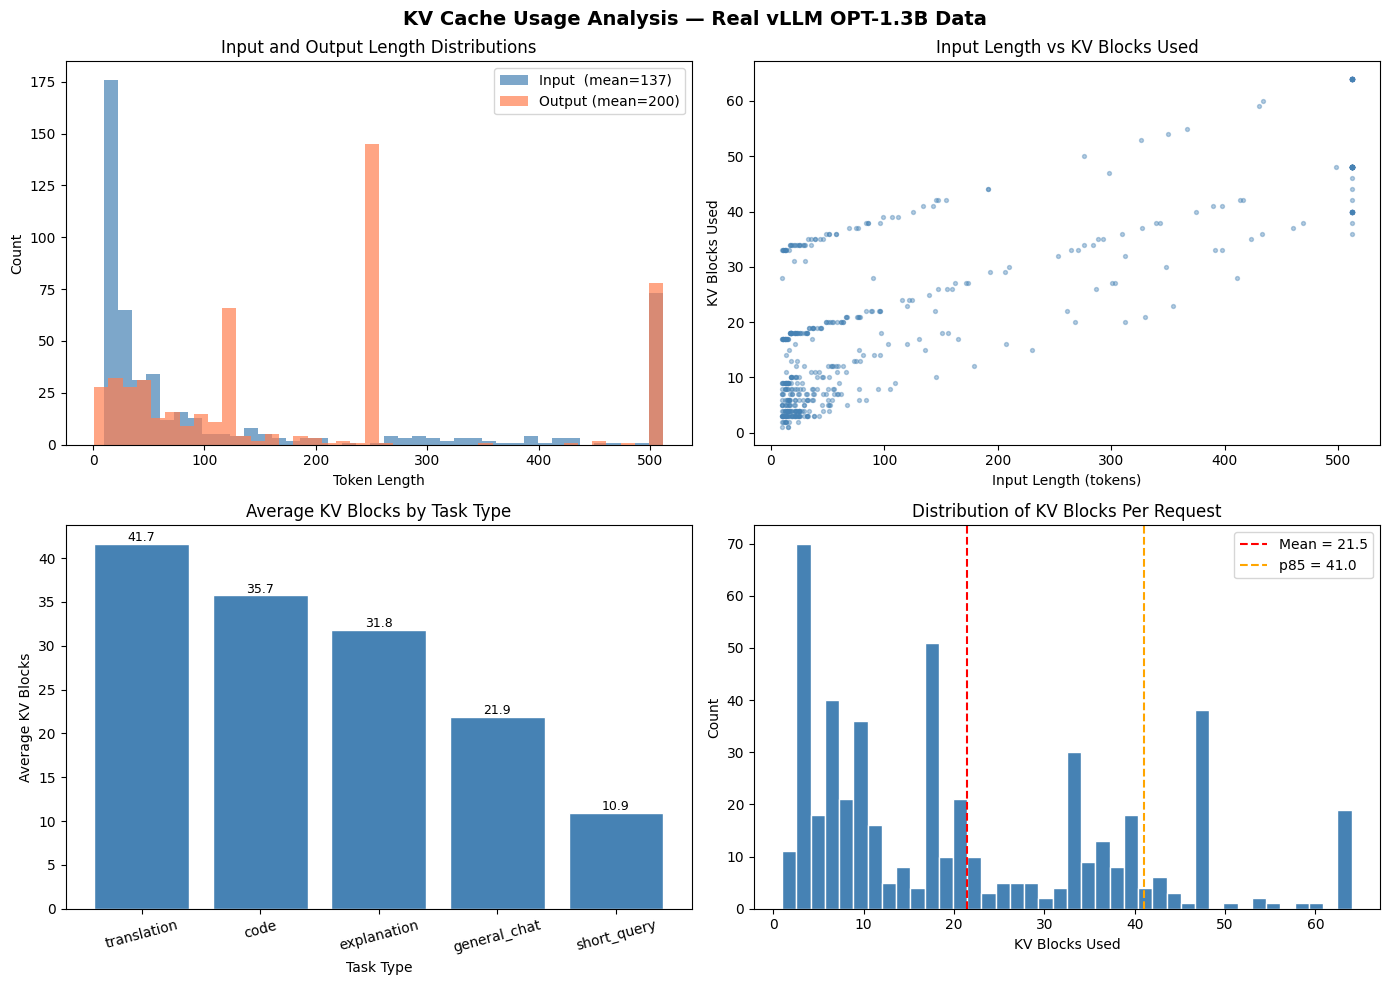

Saved plot1_eda.png


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 3 — Exploratory Data Analysis (EDA)
# Generates plots for your report
# ─────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('KV Cache Usage Analysis — Real vLLM OPT-1.3B Data',
             fontsize=14, fontweight='bold')

# Plot 1: Input vs Output length distributions
axes[0,0].hist(df['input_length'],  bins=40, alpha=0.7,
               color='steelblue', label=f"Input  (mean={df['input_length'].mean():.0f})")
axes[0,0].hist(df['actual_output_length'], bins=40, alpha=0.7,
               color='coral', label=f"Output (mean={df['actual_output_length'].mean():.0f})")
axes[0,0].set_xlabel('Token Length')
axes[0,0].set_ylabel('Count')
axes[0,0].set_title('Input and Output Length Distributions')
axes[0,0].legend()

# Plot 2: Input length vs KV blocks scatter
axes[0,1].scatter(df['input_length'], df['actual_blocks'],
                  alpha=0.4, s=8, color='steelblue')
axes[0,1].set_xlabel('Input Length (tokens)')
axes[0,1].set_ylabel('KV Blocks Used')
axes[0,1].set_title('Input Length vs KV Blocks Used')

# Plot 3: Average KV blocks by task type
task_means = df.groupby('task_type')['actual_blocks'].mean().sort_values(ascending=False)
bars = axes[1,0].bar(task_means.index, task_means.values,
                      color='steelblue', edgecolor='white')
axes[1,0].set_xlabel('Task Type')
axes[1,0].set_ylabel('Average KV Blocks')
axes[1,0].set_title('Average KV Blocks by Task Type')
axes[1,0].tick_params(axis='x', rotation=15)
for bar, val in zip(bars, task_means.values):
    axes[1,0].text(bar.get_x() + bar.get_width()/2,
                   bar.get_height() + 0.3,
                   f'{val:.1f}', ha='center', fontsize=9)

# Plot 4: KV blocks distribution
axes[1,1].hist(df['actual_blocks'], bins=40,
               color='steelblue', edgecolor='white')
axes[1,1].axvline(df['actual_blocks'].mean(), color='red',
                   linestyle='--', label=f"Mean = {df['actual_blocks'].mean():.1f}")
axes[1,1].axvline(df['actual_blocks'].quantile(0.85), color='orange',
                   linestyle='--', label=f"p85 = {df['actual_blocks'].quantile(0.85):.1f}")
axes[1,1].set_xlabel('KV Blocks Used')
axes[1,1].set_ylabel('Count')
axes[1,1].set_title('Distribution of KV Blocks Per Request')
axes[1,1].legend()

plt.tight_layout()
plt.savefig('plot1_eda.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved plot1_eda.png")

In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 4 — Prepare Features
# ─────────────────────────────────────────────────────────────

# Encode task type as numbers
le = LabelEncoder()
df['task_type_encoded'] = le.fit_transform(df['task_type'])

print("Task type encoding:")
for i, cls in enumerate(le.classes_):
    print(f"  {i} → {cls}")

# Feature columns — everything available BEFORE generation
FEATURE_COLS = [
    'input_length',
    'temperature',
    'max_tokens',
    'task_type_encoded',
    'question_marks',
    'instruction_words',
    'prompt_length_sq',
]

X = df[FEATURE_COLS]
y = df['actual_blocks']

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\nTraining samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")
print(f"\nTarget variable stats:")
print(f"  Mean   : {y.mean():.2f} blocks")
print(f"  Std    : {y.std():.2f} blocks")
print(f"  Min    : {y.min()} blocks")
print(f"  Max    : {y.max()} blocks")


Task type encoding:
  0 → code
  1 → explanation
  2 → general_chat
  3 → short_query
  4 → translation

Training samples : 400
Testing samples  : 100

Target variable stats:
  Mean   : 21.45 blocks
  Std    : 17.09 blocks
  Min    : 1 blocks
  Max    : 64 blocks


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 5 — Train All Models
# ─────────────────────────────────────────────────────────────

results  = {}   # stores metrics for all models
models   = {}   # stores trained model objects for saving

# ── Model 1: Linear Regression (baseline) ───────────────────
print("Training Linear Regression...")
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_preds = lr.predict(X_test)
lr_mae   = mean_absolute_error(y_test, lr_preds)
lr_rmse  = np.sqrt(mean_squared_error(y_test, lr_preds))
results['Linear Regression'] = {
    'MAE': lr_mae, 'RMSE': lr_rmse, 'preds': lr_preds
}
models['linear'] = lr
print(f"  MAE: {lr_mae:.2f} blocks | RMSE: {lr_rmse:.2f} blocks")

# ── Model 2: Quantile Regression (p50, p85, p95) ────────────
print("Training Quantile Regression models...")
qr_models = {}

for q in [0.50, 0.85, 0.95]:
    qr = QuantileRegressor(quantile=q, alpha=0.1, solver='highs')
    qr.fit(X_train, y_train)
    preds   = qr.predict(X_test)
    mae     = mean_absolute_error(y_test, preds)
    rmse    = np.sqrt(mean_squared_error(y_test, preds))
    label   = f'Quantile Regression (p{int(q*100)})'
    results[label] = {'MAE': mae, 'RMSE': rmse, 'preds': preds}
    qr_models[q]   = qr
    print(f"  p{int(q*100):02d} — MAE: {mae:.2f} blocks | RMSE: {rmse:.2f} blocks")

models['quantile'] = qr_models

# ── Model 3: LightGBM ────────────────────────────────────────
print("Training LightGBM...")
lgbm = lgb.LGBMRegressor(
    n_estimators  = 300,
    learning_rate = 0.05,
    num_leaves    = 31,
    min_child_samples = 10,
    random_state  = 42,
    verbose       = -1
)
lgbm.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(50, verbose=False),
               lgb.log_evaluation(period=-1)]
)
lgbm_preds = lgbm.predict(X_test)
lgbm_mae   = mean_absolute_error(y_test, lgbm_preds)
lgbm_rmse  = np.sqrt(mean_squared_error(y_test, lgbm_preds))
results['LightGBM'] = {
    'MAE': lgbm_mae, 'RMSE': lgbm_rmse, 'preds': lgbm_preds
}
models['lgbm'] = lgbm
print(f"  MAE: {lgbm_mae:.2f} blocks | RMSE: {lgbm_rmse:.2f} blocks")


Training Linear Regression...
  MAE: 6.73 blocks | RMSE: 8.37 blocks
Training Quantile Regression models...
  p50 — MAE: 6.90 blocks | RMSE: 10.44 blocks
  p85 — MAE: 7.60 blocks | RMSE: 12.41 blocks
  p95 — MAE: 7.79 blocks | RMSE: 12.58 blocks
Training LightGBM...
  MAE: 6.43 blocks | RMSE: 8.52 blocks


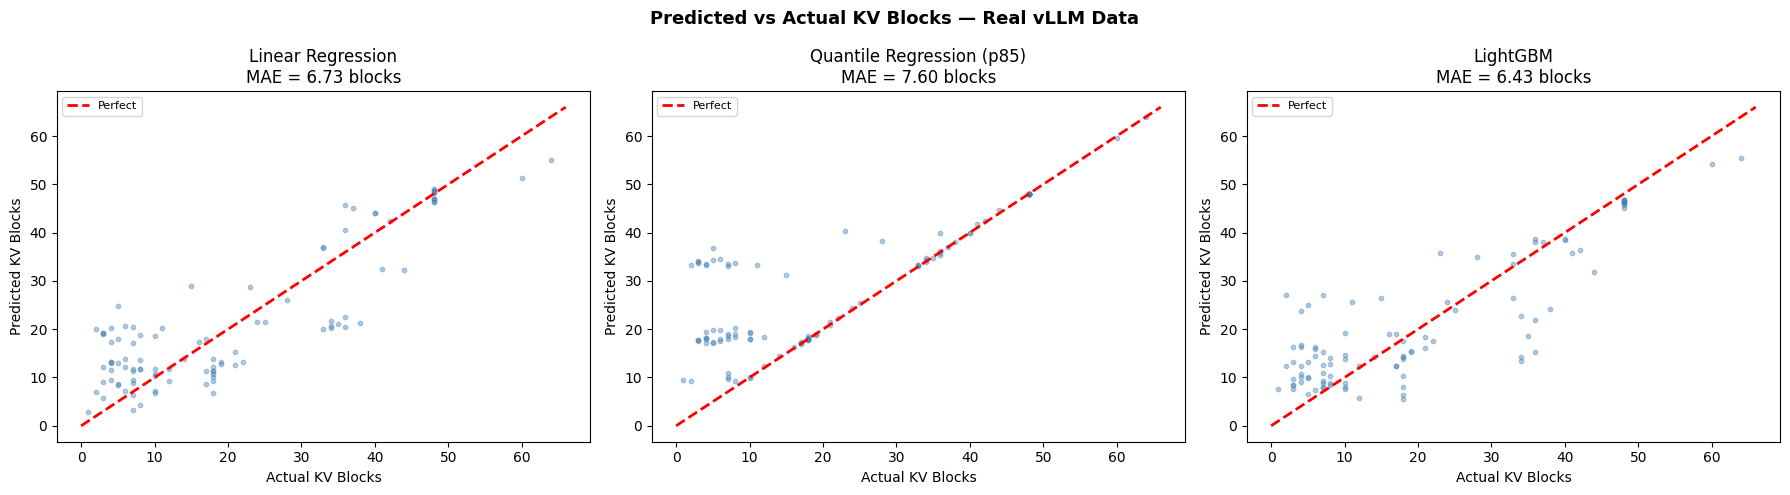

Saved plot2_predictions.png


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 6 — Prediction Accuracy Plots
# ─────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Predicted vs Actual KV Blocks — Real vLLM Data',
             fontsize=13, fontweight='bold')

plot_models = [
    ('Linear Regression',           lr_preds),
    ('Quantile Regression (p85)',
     results['Quantile Regression (p85)']['preds']),
    ('LightGBM',                    lgbm_preds),
]

for ax, (name, preds) in zip(axes, plot_models):
    mae = mean_absolute_error(y_test, preds)
    ax.scatter(y_test, preds, alpha=0.4, s=10, color='steelblue')
    max_val = max(y_test.max(), preds.max()) + 2
    ax.plot([0, max_val], [0, max_val], 'r--', lw=2, label='Perfect')
    ax.set_xlabel('Actual KV Blocks')
    ax.set_ylabel('Predicted KV Blocks')
    ax.set_title(f'{name}\nMAE = {mae:.2f} blocks')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('plot2_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved plot2_predictions.png")

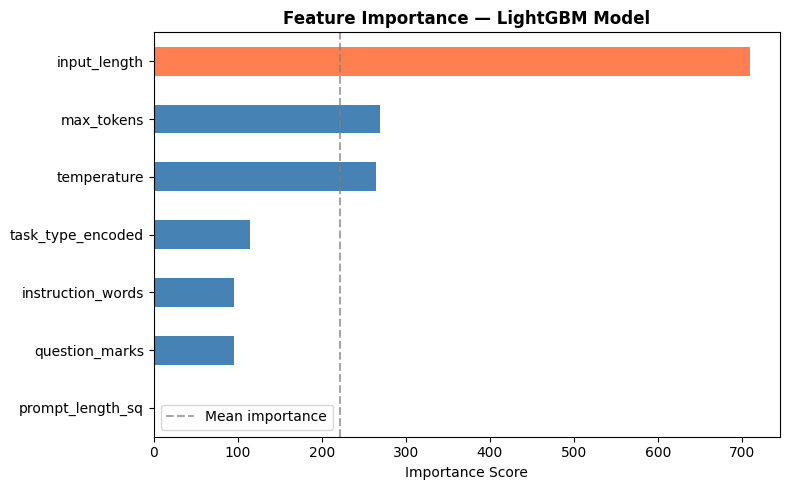

Saved plot3_feature_importance.png


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 7 — Feature Importance
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(8, 5))

importance = pd.Series(lgbm.feature_importances_, index=FEATURE_COLS)
importance_sorted = importance.sort_values()
colors = ['steelblue' if v < importance_sorted.max()
          else 'coral' for v in importance_sorted]
importance_sorted.plot(kind='barh', ax=ax, color=colors)

ax.set_title('Feature Importance — LightGBM Model', fontweight='bold')
ax.set_xlabel('Importance Score')
ax.axvline(importance_sorted.mean(), color='gray',
           linestyle='--', alpha=0.7, label='Mean importance')
ax.legend()

plt.tight_layout()
plt.savefig('plot3_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved plot3_feature_importance.png")

QUANTILE COVERAGE ANALYSIS
Quantile          Coverage   Over-alloc   Under-alloc
----------------------------------------------------------
p50 (median)         61.0%       5.83 blk        1.07 blk
p85                  86.0%       7.57 blk        0.03 blk
p95                  98.0%       7.78 blk        0.01 blk

p85 covers 86.0% of requests
with only 7.57 blocks average over-allocation


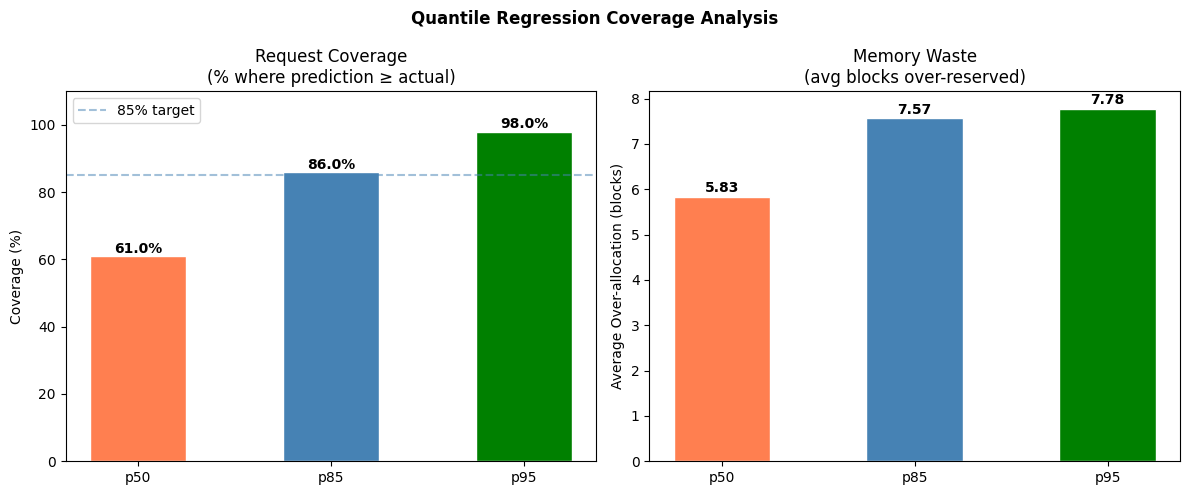

Saved plot4_coverage.png


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 8 — Quantile Coverage Analysis
# Most important metric for quantile models
# ─────────────────────────────────────────────────────────────

actual = y_test.values

p50_preds = results['Quantile Regression (p50)']['preds']
p85_preds = results['Quantile Regression (p85)']['preds']
p95_preds = results['Quantile Regression (p95)']['preds']

# Coverage = % of requests where prediction >= actual (no underallocation)
coverage_p50 = np.mean(p50_preds >= actual) * 100
coverage_p85 = np.mean(p85_preds >= actual) * 100
coverage_p95 = np.mean(p95_preds >= actual) * 100

# Over-allocation = avg extra blocks reserved unnecessarily
overalloc_p50 = np.mean(np.maximum(p50_preds - actual, 0))
overalloc_p85 = np.mean(np.maximum(p85_preds - actual, 0))
overalloc_p95 = np.mean(np.maximum(p95_preds - actual, 0))

# Under-allocation = avg blocks short (causes preemption)
underalloc_p50 = np.mean(np.maximum(actual - p50_preds, 0))
underalloc_p85 = np.mean(np.maximum(actual - p85_preds, 0))
underalloc_p95 = np.mean(np.maximum(actual - p95_preds, 0))

print("=" * 58)
print("QUANTILE COVERAGE ANALYSIS")
print("=" * 58)
print(f"{'Quantile':<15} {'Coverage':>10} {'Over-alloc':>12} {'Under-alloc':>13}")
print("-" * 58)
print(f"{'p50 (median)':<15} {coverage_p50:>9.1f}% {overalloc_p50:>10.2f} blk {underalloc_p50:>11.2f} blk")
print(f"{'p85':<15} {coverage_p85:>9.1f}% {overalloc_p85:>10.2f} blk {underalloc_p85:>11.2f} blk")
print(f"{'p95':<15} {coverage_p95:>9.1f}% {overalloc_p95:>10.2f} blk {underalloc_p95:>11.2f} blk")
print("=" * 58)
print(f"\np85 covers {coverage_p85:.1f}% of requests")
print(f"with only {overalloc_p85:.2f} blocks average over-allocation")

# Coverage plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Quantile Regression Coverage Analysis', fontweight='bold')

quantiles   = ['p50', 'p85', 'p95']
coverages   = [coverage_p50, coverage_p85, coverage_p95]
overallocs  = [overalloc_p50, overalloc_p85, overalloc_p95]
colors      = ['coral', 'steelblue', 'green']

b1 = axes[0].bar(quantiles, coverages, color=colors, edgecolor='white', width=0.5)
axes[0].set_ylabel('Coverage (%)')
axes[0].set_title('Request Coverage\n(% where prediction ≥ actual)')
axes[0].set_ylim(0, 110)
axes[0].axhline(85, color='steelblue', linestyle='--', alpha=0.5, label='85% target')
axes[0].legend()
for bar, val in zip(b1, coverages):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 1, f'{val:.1f}%',
                 ha='center', fontweight='bold')

b2 = axes[1].bar(quantiles, overallocs, color=colors, edgecolor='white', width=0.5)
axes[1].set_ylabel('Average Over-allocation (blocks)')
axes[1].set_title('Memory Waste\n(avg blocks over-reserved)')
for bar, val in zip(b2, overallocs):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.1, f'{val:.2f}',
                 ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('plot4_coverage.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved plot4_coverage.png")


SCHEDULING SIMULATION RESULTS
(Available GPU KV cache pool: 200 blocks)
Strategy                    Admitted    Util%   Preemptions
----------------------------------------------------------
Existing (Max Reserve)             7    82.5%             0
Ours (ML Predicted)               25    95.0%             0
Oracle (Perfect)                  38    98.0%             0

Improvement over existing system:
  Requests admitted : +257.1%
  Memory utilization: +12.5%


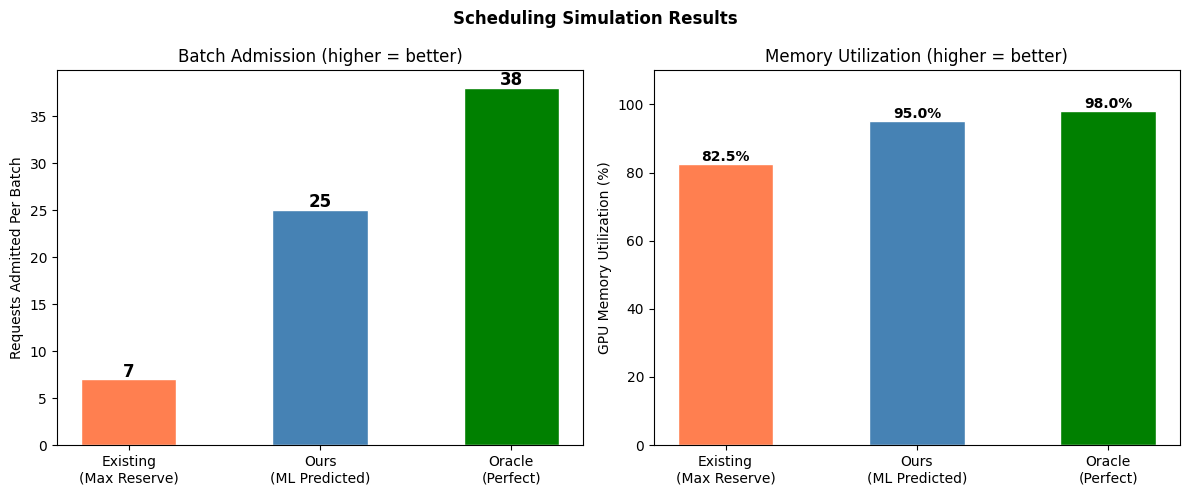

Saved plot5_scheduling.png


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 9 — Scheduling Simulation
# Shows the core benefit of ML prediction
# ─────────────────────────────────────────────────────────────

AVAILABLE_BLOCKS = 200   # simulated GPU KV cache pool
BLOCK_SIZE_SIM   = 16    # tokens per block

def simulate_scheduler(test_df, strategy, model_preds=None):
    """
    Simulate how many requests fit in one batch.

    strategy options:
      'max'       — existing system, reserves MAX_SEQ_LEN blocks per request
      'predicted' — our ML model, sorts by predicted size (Shortest Job First)
      'oracle'    — perfect knowledge of actual blocks needed
    """
    n = len(test_df)

    if strategy == 'predicted':
        # Shortest Job First using ML predictions
        order = np.argsort(model_preds)
    elif strategy == 'oracle':
        # Shortest Job First using actual sizes (theoretical upper bound)
        order = np.argsort(test_df['actual_blocks'].values)
    else:
        # Existing system — FCFS, assumes max blocks every time
        order = np.arange(n)

    admitted     = 0
    memory_used  = 0
    preemptions  = 0
    MAX_BLOCKS   = (512 + 512) // BLOCK_SIZE_SIM  # worst case = 64 blocks

    for idx in order:
        actual = test_df['actual_blocks'].iloc[idx]

        if strategy == 'predicted':
            estimated = max(int(np.ceil(model_preds[idx])), 1)
        elif strategy == 'oracle':
            estimated = actual
        else:
            estimated = MAX_BLOCKS  # existing system always assumes worst case

        if memory_used + estimated <= AVAILABLE_BLOCKS:
            admitted    += 1
            memory_used += actual   # actual memory consumed

            # Check for over-run (prediction was too low)
            if memory_used > AVAILABLE_BLOCKS:
                preemptions += 1
                memory_used -= actual
                admitted    -= 1

    utilization = (memory_used / AVAILABLE_BLOCKS) * 100
    return admitted, round(utilization, 1), preemptions

# Run simulation on test set
test_df      = df.iloc[X_test.index].reset_index(drop=True)
lgbm_test    = lgbm.predict(X_test)

adm_max,   util_max,  pre_max  = simulate_scheduler(test_df, 'max')
adm_pred,  util_pred, pre_pred = simulate_scheduler(test_df, 'predicted', lgbm_test)
adm_ora,   util_ora,  pre_ora  = simulate_scheduler(test_df, 'oracle')

improvement_adm  = ((adm_pred  - adm_max)  / max(adm_max,  1)) * 100
improvement_util = util_pred - util_max

print("\n" + "=" * 58)
print("SCHEDULING SIMULATION RESULTS")
print(f"(Available GPU KV cache pool: {AVAILABLE_BLOCKS} blocks)")
print("=" * 58)
print(f"{'Strategy':<25} {'Admitted':>10} {'Util%':>8} {'Preemptions':>13}")
print("-" * 58)
print(f"{'Existing (Max Reserve)':<25} {adm_max:>10} {util_max:>7.1f}% {pre_max:>13}")
print(f"{'Ours (ML Predicted)':<25} {adm_pred:>10} {util_pred:>7.1f}% {pre_pred:>13}")
print(f"{'Oracle (Perfect)':<25} {adm_ora:>10} {util_ora:>7.1f}% {pre_ora:>13}")
print("=" * 58)
print(f"\nImprovement over existing system:")
print(f"  Requests admitted : +{improvement_adm:.1f}%")
print(f"  Memory utilization: +{improvement_util:.1f}%")

# Scheduling results plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Scheduling Simulation Results', fontweight='bold')

strategies     = ['Existing\n(Max Reserve)', 'Ours\n(ML Predicted)', 'Oracle\n(Perfect)']
admitted_vals  = [adm_max,   adm_pred,  adm_ora]
util_vals      = [util_max,  util_pred, util_ora]
colors         = ['coral', 'steelblue', 'green']

b1 = axes[0].bar(strategies, admitted_vals, color=colors, edgecolor='white', width=0.5)
axes[0].set_ylabel('Requests Admitted Per Batch')
axes[0].set_title('Batch Admission (higher = better)')
for bar, val in zip(b1, admitted_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 str(val), ha='center', fontweight='bold', fontsize=12)

b2 = axes[1].bar(strategies, util_vals, color=colors, edgecolor='white', width=0.5)
axes[1].set_ylabel('GPU Memory Utilization (%)')
axes[1].set_title('Memory Utilization (higher = better)')
axes[1].set_ylim(0, 110)
for bar, val in zip(b2, util_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 1,
                 f'{val:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('plot5_scheduling.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved plot5_scheduling.png")


In [ ]:
# ─────────────────────────────────────────────────────────────
# CELL 10 — Final Summary + Save Models
# ─────────────────────────────────────────────────────────────

print("\n" + "=" * 58)
print("FINAL RESULTS SUMMARY")
print("=" * 58)
print(f"Dataset        : ShareGPT real vLLM OPT-1.3B ({len(df)} requests)")
print(f"Block size     : {BLOCK_SIZE_SIM} tokens/block")
print(f"Train/Test     : 80/20 split\n")

print("── Prediction Accuracy ─────────────────────────────")
for name, res in results.items():
    print(f"  {name:<35} MAE = {res['MAE']:.2f} blk | RMSE = {res['RMSE']:.2f} blk")

print("\n── Quantile Coverage ───────────────────────────────")
print(f"  p50 coverage: {coverage_p50:.1f}% | over-alloc: {overalloc_p50:.2f} blk")
print(f"  p85 coverage: {coverage_p85:.1f}% | over-alloc: {overalloc_p85:.2f} blk")
print(f"  p95 coverage: {coverage_p95:.1f}% | over-alloc: {overalloc_p95:.2f} blk")

print("\n── Scheduling Improvement ──────────────────────────")
print(f"  Existing system  : {adm_max} requests admitted, {util_max:.1f}% util")
print(f"  Ours (ML)        : {adm_pred} requests admitted, {util_pred:.1f}% util")
print(f"  Oracle (perfect) : {adm_ora} requests admitted, {util_ora:.1f}% util")
print(f"  Improvement      : +{improvement_adm:.1f}% admission, +{improvement_util:.1f}% utilization")
print("=" * 58)

# Save all trained models + encoder to disk
# Script 3 will load these for the scheduling simulation
save_data = {
    'models'        : models,
    'label_encoder' : le,
    'feature_cols'  : FEATURE_COLS,
    'results'       : {k: {'MAE': v['MAE'], 'RMSE': v['RMSE']}
                       for k, v in results.items()},  # exclude preds array
    'coverage'      : {
        'p50': {'coverage': coverage_p50, 'overalloc': overalloc_p50},
        'p85': {'coverage': coverage_p85, 'overalloc': overalloc_p85},
        'p95': {'coverage': coverage_p95, 'overalloc': overalloc_p95},
    },
    'scheduling'    : {
        'max'       : {'admitted': adm_max,  'utilization': util_max,  'preemptions': pre_max},
        'predicted' : {'admitted': adm_pred, 'utilization': util_pred, 'preemptions': pre_pred},
        'oracle'    : {'admitted': adm_ora,  'utilization': util_ora,  'preemptions': pre_ora},
    }
}

with open("models.pkl", "wb") as f:
    pickle.dump(save_data, f)

print("\nModels saved to models.pkl")
print("Plots saved: plot1_eda.png, plot2_predictions.png,")
print("             plot3_feature_importance.png,")
print("             plot4_coverage.png, plot5_scheduling.png")
print("\nScript 2 complete! Run Script 3 next.")


FINAL RESULTS SUMMARY
Dataset        : ShareGPT real vLLM OPT-1.3B (500 requests)
Block size     : 16 tokens/block
Train/Test     : 80/20 split

── Prediction Accuracy ─────────────────────────────
  Linear Regression                   MAE = 6.73 blk | RMSE = 8.37 blk
  Quantile Regression (p50)           MAE = 6.90 blk | RMSE = 10.44 blk
  Quantile Regression (p85)           MAE = 7.60 blk | RMSE = 12.41 blk
  Quantile Regression (p95)           MAE = 7.79 blk | RMSE = 12.58 blk
  LightGBM                            MAE = 6.43 blk | RMSE = 8.52 blk

── Quantile Coverage ───────────────────────────────
  p50 coverage: 61.0% | over-alloc: 5.83 blk
  p85 coverage: 86.0% | over-alloc: 7.57 blk
  p95 coverage: 98.0% | over-alloc: 7.78 blk

── Scheduling Improvement ──────────────────────────
  Existing system  : 7 requests admitted, 82.5% util
  Ours (ML)        : 25 requests admitted, 95.0% util
  Oracle (perfect) : 38 requests admitted, 98.0% util
  Improvement      : +257.1% admission,